# Immuno Compass · Notebook 11: What drives ADA? Do the three methods agree? (Day 14)

**Goal:** read each model's explanation and check whether the **GLM**, the **Bayesian Beta-Binomial** and **XGBoost**
point to the same factors.

| Model | How it explains itself |
|---|---|
| GLM | odds ratios with **cluster-robust** 95 % confidence intervals (clusters = molecules) |
| Bayesian Beta-Binomial | posterior odds ratios with 94 % **credible** intervals (`az.plot_forest`) |
| XGBoost | **SHAP** values: for each cohort, how much each clue pushed the prediction up or down |

All three use the same standardised features, fitted on **all** cohorts (interpretation, not prediction).
Everything here is an **association** in observational trial data, **not** a cause.

> 🧒 *Simple version:* three detectives looked at the same case. Do they accuse the same suspects?

In [1]:
# ---- Setup: works both in Colab and on a laptop ----
import sys, os
from pathlib import Path

if "google.colab" in sys.modules and not Path("/content/immuno-compass").exists():
    # The repo is private, so Colab needs a GitHub token once per session.
    # Make one at github.com/settings/tokens (fine-grained, read access to immuno-compass).
    from getpass import getpass
    token = getpass("GitHub token: ")
    !git clone -q https://{token}@github.com/shibilshamz/immuno-compass.git /content/immuno-compass
    del token
if "google.colab" in sys.modules:
    os.chdir("/content/immuno-compass")
    !pip install -q statsmodels xgboost shap arviz

# Make the shared helper module (src/immuno.py) importable from any folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "immuno.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import immuno as im
print("repo root:", ROOT.name)

repo root: immuno-compass


In [2]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import arviz as az, joblib, shap
np.random.seed(42)
for msg in ["Found unknown categories", ".*BLAS.*"]:
    warnings.filterwarnings("ignore", message=msg)
warnings.filterwarnings("ignore", category=FutureWarning)

df = im.load_cohorts(ROOT)
BLUE, ORANGE, AQUA, GRAY, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "savefig.dpi": 200, "savefig.bbox": "tight", "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID})

FEATURE_LABEL = {"route": "Route", "indication": "Disease", "modality": "Drug type", "species": "Origin",
                 "backbone": "Backbone", "expression": "Made in", "blinding": "Blinding", "randomized": "Randomised",
                 "comparator": "Comparator"}
SINGLE = {"log_dose_mgkg": "Dose", "start_year": "Trial start year", "log_followup_days": "Follow-up length",
          "co_immunosuppressant": "With immunosuppressant", "co_any_drug": "With any co-medication",
          "arm_mentions_placebo": "Arm mentions placebo", "biosimilar": "Biosimilar"}
def nice(col):
    if col in SINGLE: return SINGLE[col]
    if col.startswith("missingindicator_"): return SINGLE.get(col[17:], col[17:]) + " (missing)"
    feat = next(c for c in im.CAT_FEATURES if col.startswith(c + "_"))
    return f"{FEATURE_LABEL[feat]}: {col[len(feat) + 1:]} (vs {im.REFERENCE[feat].replace('Chinese hamster ovary (CHO) cells', 'CHO')})"

/usr/local/lib/python3.11/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1 · GLM: cluster-robust odds ratios (same scale as the Bayesian model: categories vs reference, numbers/flags per 1 SD)

In [3]:
pre = im.make_preprocessor(scale=True).fit(df)
cols = list(pre.get_feature_names_out())
X = sm.add_constant(pd.DataFrame(pre.transform(df), columns=cols))
glm = sm.GLM(np.column_stack([df["y"], df["n"] - df["y"]]), X, family=sm.families.Binomial()).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(df[im.GROUP])[0]})
ci = glm.conf_int()
glm_tab = pd.DataFrame({"glm_OR": np.exp(glm.params), "glm_lo": np.exp(ci[0]), "glm_hi": np.exp(ci[1])}).drop(index="const")
print(f"GLM: intervals excluding 1 → {((glm_tab.glm_lo > 1) | (glm_tab.glm_hi < 1)).sum()} of {len(glm_tab)}")

GLM: intervals excluding 1 → 10 of 42


## 2 · Bayesian Beta-Binomial: posterior odds ratios (forest plot)

Beta-Binomial: 94 % intervals excluding 1 → 18 of 42


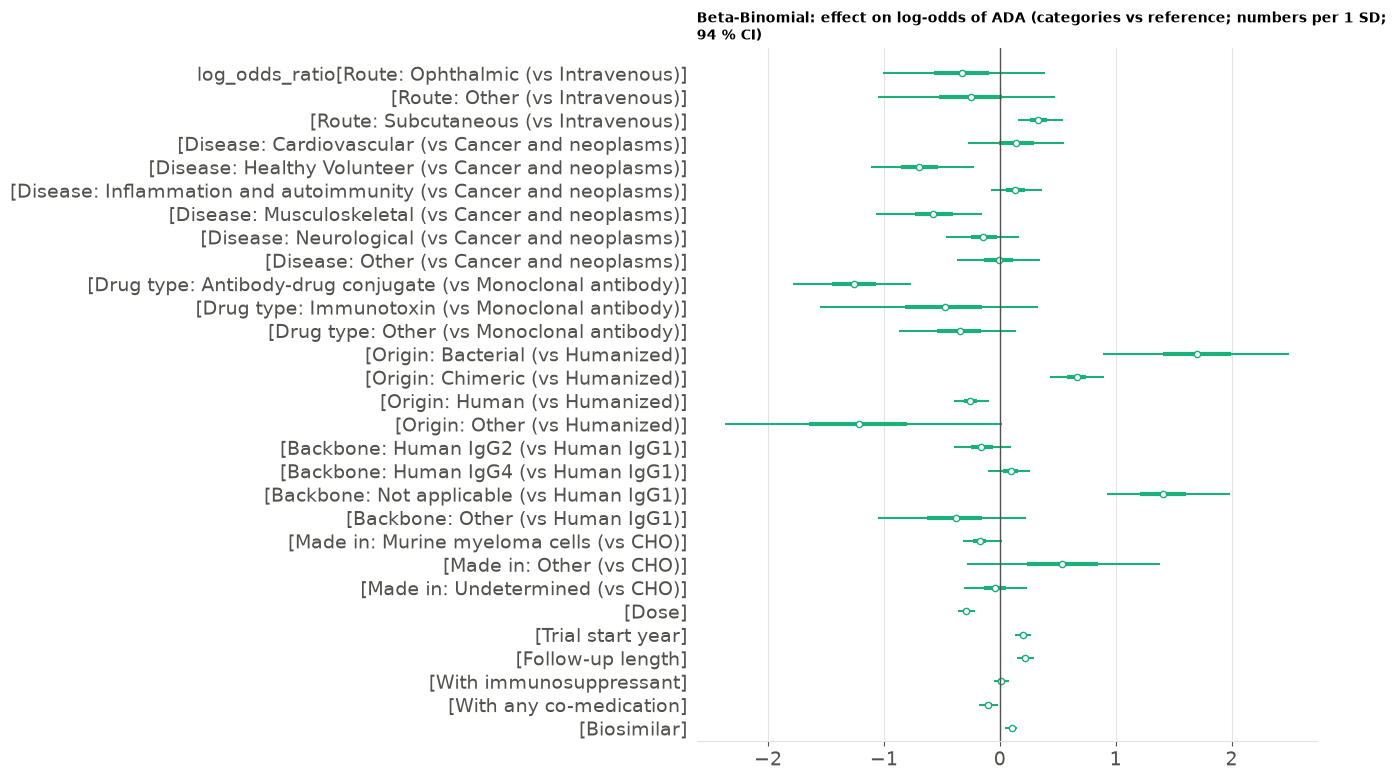

In [4]:
bb = joblib.load(ROOT / "models" / "bayes_betabinomial.joblib")
assert bb["columns"] == cols, "the saved Bayesian model uses a different feature layout"
beta = bb["beta"]                                                         # (1000 draws, features)
bayes_tab = pd.DataFrame({"bayes_OR": np.exp(beta).mean(0), "bayes_lo": np.exp(np.percentile(beta, 3, 0)),
                          "bayes_hi": np.exp(np.percentile(beta, 97, 0)), "P(up)": (beta > 0).mean(0)}, index=cols)
print(f"Beta-Binomial: 94 % intervals excluding 1 → {((bayes_tab.bayes_lo > 1) | (bayes_tab.bayes_hi < 1)).sum()} of {len(bayes_tab)}")

show = [c for c in cols if not c.startswith(("missingindicator_", "blinding_", "randomized_", "comparator_", "arm_mentions"))]
idata = az.from_dict(posterior={"log_odds_ratio": beta[None, :, [cols.index(c) for c in show]]},
                     coords={"feature": [nice(c) for c in show]}, dims={"log_odds_ratio": ["feature"]})
axes = az.plot_forest(idata, combined=True, hdi_prob=0.94, colors=AQUA, figsize=(8, 9))
axes[0].axvline(0, color=INK2, lw=1)
axes[0].set_title("Beta-Binomial: effect on log-odds of ADA (categories vs reference; numbers per 1 SD; 94 % CI)", fontsize=10, loc="left", fontweight="bold")
plt.savefig(ROOT / "figures" / "interp_bayes_forest.png"); plt.show()

## 3 · XGBoost: SHAP values

**SHAP** splits each prediction into contributions from each clue, measured in log-odds. Positive pushes the predicted
ADA up; negative pushes it down. Averaging |SHAP| over cohorts gives a fair importance ranking. Unlike "gain", it also
shows **direction**.

XGBoost setting: {'max_depth': 2, 'weight': 'sqrt_n'} | extra features: []


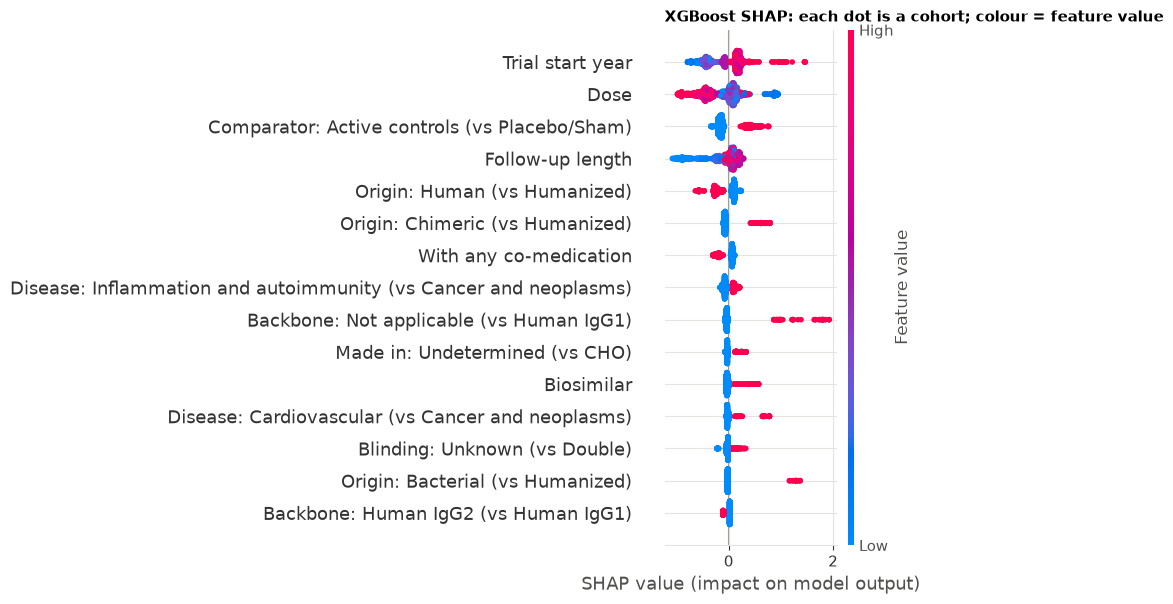

In [5]:
saved = joblib.load(ROOT / "models" / "xgb_model.joblib")
pre_x, xgb = saved["preprocessor"], saved["model"]
print("XGBoost setting:", saved["config"], "| extra features:", saved.get("extra_num", []))
X_raw = pd.DataFrame(pre_x.transform(df), columns=pre_x.get_feature_names_out())
explainer = shap.TreeExplainer(xgb)
sv = explainer.shap_values(X_raw)                                         # (cohorts, columns), log-odds units

shap.summary_plot(sv, X_raw.rename(columns=lambda c: nice(c) if not c.startswith("seq_") else c),
                  max_display=15, show=False, plot_size=(9, 6))
plt.title("XGBoost SHAP: each dot is a cohort; colour = feature value", loc="left", fontweight="bold", fontsize=11)
plt.savefig(ROOT / "figures" / "interp_shap_summary.png"); plt.show()

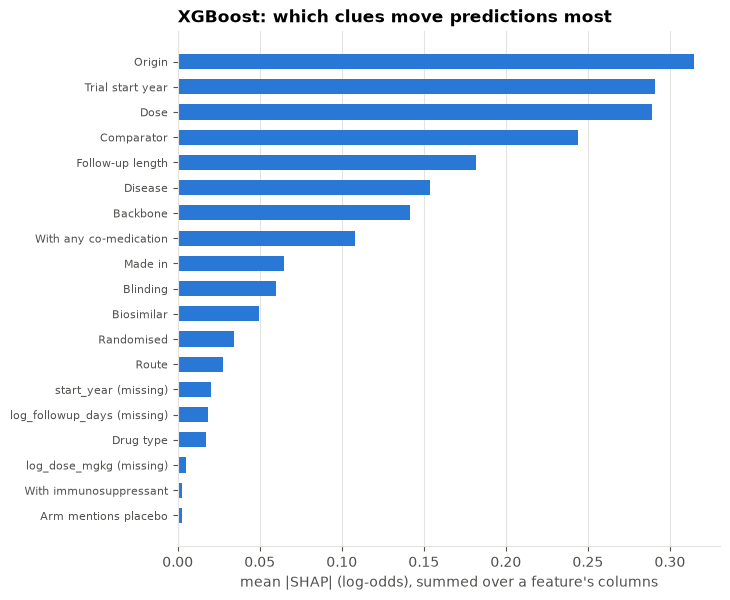

In [6]:
def base_feature(col):
    if col.startswith("missingindicator_"): return col[17:] + " (missing)"
    return next((c for c in im.CAT_FEATURES if col.startswith(c + "_")), col)

imp = pd.Series(np.abs(sv).mean(0), index=X_raw.columns).groupby(base_feature).sum().sort_values()
fig, ax = plt.subplots(figsize=(7, 0.3 * len(imp) + 1))
ax.barh(range(len(imp)), imp.values, color=BLUE, height=0.6)
ax.set_yticks(range(len(imp)), [SINGLE.get(i, FEATURE_LABEL.get(i, i)) for i in imp.index], fontsize=8)
ax.set_xlabel("mean |SHAP| (log-odds), summed over a feature's columns"); ax.grid(axis="y", visible=False)
ax.set_title("XGBoost: which clues move predictions most")
fig.savefig(ROOT / "figures" / "interp_shap_importance.png"); plt.show()

## 4 · Do the three methods agree?

For each feature column we record each method's **direction** (↑ more ADA / ↓ less ADA) and whether it is **confident**:
* GLM: cluster-robust 95 % CI excludes OR = 1
* Bayes: 94 % credible interval excludes OR = 1
* XGBoost: direction = sign of the correlation between the column's value and its SHAP value; "strong" = top-10 mean |SHAP|

In [7]:
xgb_dir = {}
for c in X_raw.columns:
    v = X_raw[c].values
    xgb_dir[c] = np.sign(np.corrcoef(v, sv[:, list(X_raw.columns).index(c)])[0, 1]) if v.std() > 0 else 0.0
top10 = pd.Series(np.abs(sv).mean(0), index=X_raw.columns).nlargest(10).index

agree = glm_tab.join(bayes_tab).loc[[c for c in cols if c in X_raw.columns]]
agree["GLM"] = np.where(agree.glm_OR > 1, "↑", "↓") + np.where((agree.glm_lo > 1) | (agree.glm_hi < 1), " ✔", "")
agree["Bayes"] = np.where(agree.bayes_OR > 1, "↑", "↓") + np.where((agree.bayes_lo > 1) | (agree.bayes_hi < 1), " ✔", "")
agree["XGBoost"] = [("↑" if xgb_dir[c] > 0 else "↓" if xgb_dir[c] < 0 else "–") + (" ★" if c in top10 else "") for c in agree.index]
dirs = pd.DataFrame({"g": np.sign(np.log(agree.glm_OR)), "b": np.sign(np.log(agree.bayes_OR)), "x": [xgb_dir[c] for c in agree.index]}, index=agree.index)
agree["all 3 same direction"] = (dirs.nunique(axis=1) == 1)
conf = ((agree.glm_lo > 1) | (agree.glm_hi < 1)) & ((agree.bayes_lo > 1) | (agree.bayes_hi < 1))
agree["robust finding"] = agree["all 3 same direction"] & conf
agree.index = [nice(c) for c in agree.index]
print(f"same direction in all three: {agree['all 3 same direction'].sum()} of {len(agree)} | "
      f"same direction AND confident in both GLM and Bayes: {agree['robust finding'].sum()}")
display(agree[["glm_OR", "GLM", "bayes_OR", "Bayes", "XGBoost", "all 3 same direction", "robust finding"]]
        .sort_values(["robust finding", "all 3 same direction"], ascending=False)
        .style.format({"glm_OR": "{:.2f}", "bayes_OR": "{:.2f}"})
        .apply(lambda r: ["background-color:#e6f4ea" if r["robust finding"] else "" for _ in r], axis=1))

same direction in all three: 32 of 42 | same direction AND confident in both GLM and Bayes: 9


/usr/local/lib/python3.11/dist-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.11/dist-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,glm_OR,GLM,bayes_OR,Bayes,XGBoost,all 3 same direction,robust finding
Disease: Healthy Volunteer (vs Cancer and neoplasms),0.31,↓ ✔,0.52,↓ ✔,–,True,True
Comparator: Active controls (vs Placebo/Sham),2.58,↑ ✔,2.29,↑ ✔,↑ ★,True,True
Origin: Bacterial (vs Humanized),45.32,↑ ✔,6.06,↑ ✔,↑,True,True
Origin: Other (vs Humanized),0.10,↓ ✔,0.35,↓ ✔,–,True,True
Dose,0.75,↓ ✔,0.75,↓ ✔,↓ ★,True,True
Trial start year,1.70,↑ ✔,1.22,↑ ✔,↑ ★,True,True
Trial start year (missing),1.18,↑ ✔,1.12,↑ ✔,↑,True,True
With any co-medication,0.78,↓ ✔,0.91,↓ ✔,↓ ★,True,True
Biosimilar,1.16,↑ ✔,1.11,↑ ✔,↑,True,True
Route: Other (vs Intravenous),0.40,↓,0.84,↓,–,True,False


## 5 · Day 14 findings (write-up)

**Agreement:** **32 of 42** feature columns point the same way in all three methods (GLM, Bayesian Beta-Binomial, XGBoost SHAP). **9** are also confidently non-zero in *both* the GLM (cluster-robust) and the Bayesian model.

**Robust associations (same direction in all three, confident in GLM and Bayes):**

| factor | direction | plausible explanation (association, not cause) |
|---|---|---|
| Later trial start year | ↑ more ADA | more sensitive, drug-tolerant ADA assays in newer trials |
| Higher dose | ↓ less ADA | high-dose tolerance; also high drug levels can mask ADA in older assays |
| Bacterial origin (vs humanized) | ↑ much more | bacterial proteins look very foreign to the human immune system |
| Active-controlled trials | ↑ more | mostly biosimilar head-to-head trials of high-ADA molecules with sensitive assays |
| Biosimilar product | ↑ more | same reason: newer, more sensitive testing in biosimilar programmes |
| Any co-medication | ↓ less | combination regimens (incl. chemotherapy, immunosuppressants) damp immune responses |
| Healthy volunteers (vs cancer) | ↓ less | short, often single-dose exposure gives fewer chances to develop ADA |

(Also flagged but not interpreted: "Origin: Other" is a single drug, and "start year missing" is a data artefact.)

**Consistent direction, confident in the Bayesian model only (supportive, not conclusive):** the **"foreignness" gradient**, with chimeric ↑ and fully human ↓ vs humanized; **subcutaneous ↑ vs IV**; **longer follow-up ↑**; **antibody-drug conjugates ↓**; non-antibody proteins ↑. All match established biology, but the cluster-robust GLM can't confirm them with ~108 molecules.

**Disagreements / no clear effect:** co-administered immunosuppressants (no consistent direction once disease area is accounted for), IgG4 vs IgG1, expression system, and several study-design categories. These levels involve few molecules or are confounded with drug type.

**SHAP (XGBoost)** ranks trial start year, dose, active-control design, follow-up length and drug origin (human / chimeric) as the biggest drivers of individual predictions, the same core set the statistical models found.

**Bottom line for the presentation:** three very different methods agree on a short list of factors: **assay era, dose, protein foreignness, trial type and co-medication**. That agreement gives confidence that these are real patterns in the IDC data. They remain **associations in observational trial data**, and several (year, biosimilar, active control) probably reflect **how ADA is measured** rather than biology.